# Grouped (Clustered) Bar Chart

**Family:** Magnitude &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Magnitude:* Compare sizes, relative or absolute (usually counts rather than rates).

## Design purpose

Places bars for several sub-groups side by side within each category. Sub-groups can be compared within a category, and the same sub-group across categories.

## When to use

- Compare 2–4 sub-groups across a handful of categories (sales by region and year)
- Individual values matter more than the category total

## Avoid when

- There are more than ~4 sub-groups or ~8 categories (it becomes a barcode; use small multiples)
- The total of each category is the main point (use stacked bars)

## Alternatives

- Dumbbell chart (2 sub-groups)
- Small-multiple bar charts
- Stacked bar

## Design tips

- Keep a small gap between bars in a group and a larger gap between groups
- Use consistent colors for each sub-group across all charts

## Example

Sales by region for three consecutive years.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
pio.templates["vizlib"] = go.layout.Template(layout=dict(
    colorway=PALETTE, font=dict(family="Helvetica, Arial, sans-serif", size=13, color="#0b0b0b"),
    paper_bgcolor="#fcfcfb", plot_bgcolor="#fcfcfb", title=dict(x=0.02, xanchor="left"),
    xaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
    yaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
))
pio.templates.default = "plotly_white+vizlib"

import numpy as np
import pandas as pd
import altair as alt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]


@alt.theme.register("vizlib", enable=True)
def vizlib_theme():
    return alt.theme.ThemeConfig({
        "config": {
            "background": "#fcfcfb",
            "view": {"stroke": None},
            "range": {"category": PALETTE},
            "font": "Helvetica, Arial, sans-serif",
            "title": {"anchor": "start", "fontSize": 14, "color": "#0b0b0b"},
            "axis": {"gridColor": "#e6e5e1", "domainColor": "#c9c8c3", "tickColor": "#c9c8c3",
                     "labelColor": "#52514e", "titleColor": "#52514e", "titleFontWeight": "normal"},
            "legend": {"labelColor": "#52514e", "titleColor": "#52514e"},
        }
    })
pio.renderers.default = "plotly_mimetype+notebook_connected"

### Data

In [2]:
df = pd.DataFrame({
    "region": ["North", "South", "East", "West", "Central"],
    "2022": [42, 35, 28, 50, 22],
    "2023": [48, 33, 34, 55, 25],
    "2024": [55, 31, 41, 57, 30],
}).set_index("region")
labels = dict(y="Sales ($M)", legend="Year", title="Sales by region and year")
df

,2022,2023,2024
region,,,
North,42,48,55
South,35,33,31
East,28,34,41
West,50,55,57
Central,22,25,30


### Plot

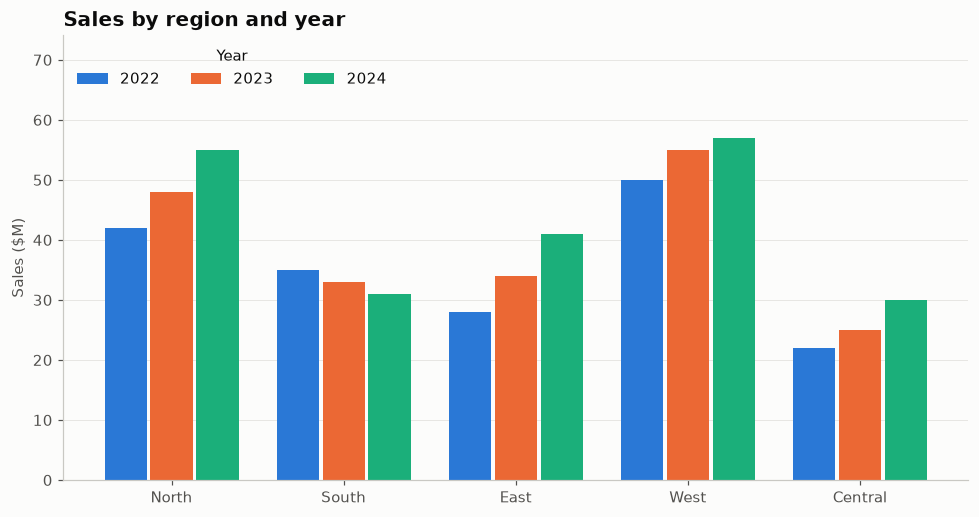

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.8))
n = len(df.columns)
width = 0.8 / n
x = np.arange(len(df))
for i, col in enumerate(df.columns):
    ax.bar(x + (i - (n - 1) / 2) * width, df[col], width=width * 0.92,
           color=PALETTE[i], label=col)
ax.set_xticks(x, df.index)
ax.set_ylabel(labels["y"])
ax.grid(axis="x", visible=False)
ax.legend(title=labels["legend"], ncol=n, loc="upper left")
ax.set_ylim(0, df.values.max() * 1.3)
ax.set_title(labels["title"])
fig.tight_layout()
plt.show()

## The same chart in other libraries

Each version uses the example data above. Pick the library that fits your stack: matplotlib/seaborn for static and print figures, plotly for interactive HTML, Altair for concise declarative specs.

### plotly

In [4]:
import plotly.express as px
long = df.rename_axis("group").reset_index().melt(id_vars="group", var_name="series", value_name="value")
fig = px.bar(long, x="group", y="value", color="series", barmode="group",
             color_discrete_sequence=PALETTE, title=labels["title"],
             labels={"group": "", "value": labels["y"], "series": labels["legend"] or ""})
fig.show()

### altair

In [5]:
import altair as alt
long = df.rename_axis("group").reset_index().melt(id_vars="group", var_name="series", value_name="value")
chart = alt.Chart(long).mark_bar(cornerRadiusTopLeft=3, cornerRadiusTopRight=3).encode(
    x=alt.X("group:N", title=None, sort=list(df.index), axis=alt.Axis(labelAngle=0)),
    xOffset=alt.XOffset("series:N", sort=list(df.columns)),
    y=alt.Y("value:Q", title=labels["y"]),
    color=alt.Color("series:N", title=labels["legend"], sort=list(df.columns)),
    tooltip=["group", "series", "value"],
).properties(title=labels["title"], width=480, height=300)
chart

alt.Chart(...)

## Try it with real data

**Source:** plotly.express.data.medals_long() — 2018 Winter Olympics short-track medal counts, bundled with plotly

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [6]:
import plotly.express as px
m = px.data.medals_long()
df = (m.pivot(index="nation", columns="medal", values="count")[["gold", "silver", "bronze"]]
        .rename(columns=str.title).rename_axis(index=None, columns=None))
labels = dict(y="Medals", legend=None, title="2018 Winter Olympics short-track medals")
df

,Gold,Silver,Bronze
Canada,9,12,12
China,10,15,8
South Korea,24,13,11


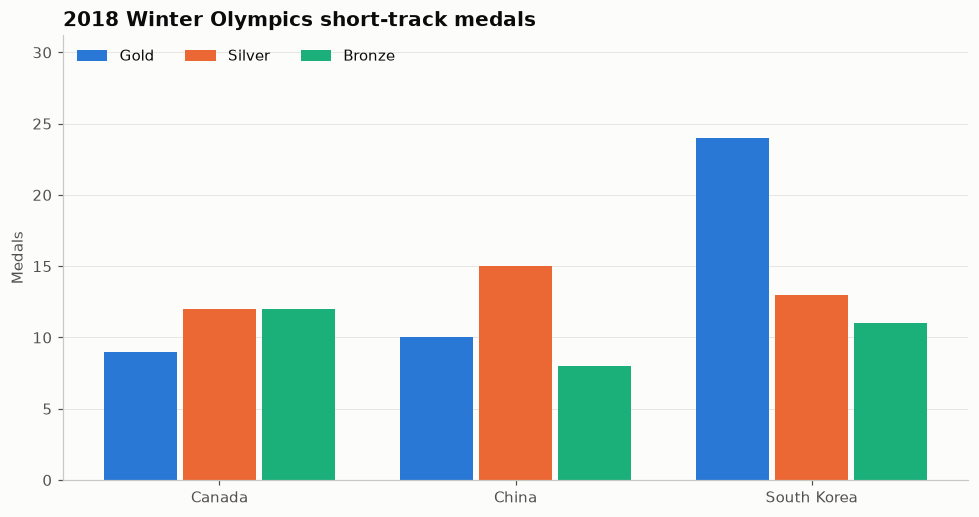

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.8))
n = len(df.columns)
width = 0.8 / n
x = np.arange(len(df))
for i, col in enumerate(df.columns):
    ax.bar(x + (i - (n - 1) / 2) * width, df[col], width=width * 0.92,
           color=PALETTE[i], label=col)
ax.set_xticks(x, df.index)
ax.set_ylabel(labels["y"])
ax.grid(axis="x", visible=False)
ax.legend(title=labels["legend"], ncol=n, loc="upper left")
ax.set_ylim(0, df.values.max() * 1.3)
ax.set_title(labels["title"])
fig.tight_layout()
plt.show()

---
Standalone script: [`grouped_bar.py`](grouped_bar.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)